In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q openpyxl scikit-learn seaborn

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
# ============================================================
# CONFIG
# ============================================================
MANIFEST_PATH = '/content/drive/MyDrive/banana_processed/manifest.csv'
DATASET_ROOT  = '/content/drive/MyDrive/banana_processed'

BATCH_SIZE  = 16
NUM_WORKERS = 2
IMG_SIZE    = 224
EPOCHS      = 30
PATIENCE    = 7
LR          = 1e-3
WEIGHT_DECAY= 1e-4

df = pd.read_csv(MANIFEST_PATH)
df['y_bin'] = df['class'].str.lower().str.strip().map(
    lambda s: 1 if s.startswith('adult') else 0
)

print('Total samples:', len(df))
print('\nClass distribution:')
print(df['y_bin'].value_counts().rename(index={0:'Natural', 1:'Adulterated'}))
print('\nSplit distribution:')
print(df['split'].value_counts())
print('\nSplit × Class:')
print(pd.crosstab(df['split'], df['y_bin']))

Total samples: 2847

Class distribution:
y_bin
Natural        1512
Adulterated    1335
Name: count, dtype: int64

Split distribution:
split
train    1803
test      531
val       513
Name: count, dtype: int64

Split × Class:
y_bin    0    1
split          
test   311  220
train  978  825
val    223  290


In [ ]:
# ============================================================
# Robust npz path resolver
# ============================================================
from pathlib import Path

def resolve_npz_path(raw, root):
    raw = str(raw)
    p = Path(raw)
    if p.exists():
        return p
    stripped = raw.lstrip('/')
    if stripped.startswith('content/'):
        stripped = stripped[len('content/'):]
    for c in [Path('/content/drive/MyDrive') / stripped,
              Path(root) / Path(raw).name]:
        if c.exists():
            return c
    raise FileNotFoundError(f'Cannot resolve: {raw}')


# ============================================================
# Dataset — corrected shape/dtype handling
# ============================================================
class BananaMultimodalDataset(Dataset):
    def __init__(self, df, root, train=False):
        self.df = df.reset_index(drop=True)
        self.root = Path(root)
        self.train = train
        self.train_tf = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=8),
            transforms.ColorJitter(brightness=0.12, contrast=0.12,
                                   saturation=0.10, hue=0.02),
            transforms.ToTensor(),
            transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
        ])
        self.eval_tf = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.CenterCrop(IMG_SIZE),
            transforms.ToTensor(),
            transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
        ])

    def __len__(self):
        return len(self.df)

    @staticmethod
    def _to_uint8_hwc(arr, channels):
        """
        Convert any array to HWC uint8 PIL-ready.
        - If (C, H, W) -> (H, W, C)
        - If (1, H, W) -> (H, W) then replicated
        - If (H, W)    -> kept
        - Scales floats [0,1] -> [0,255]
        """
        import numpy as np

        arr = np.asarray(arr)

        # Normalize dtype
        if arr.dtype != np.uint8:
            arr = arr.astype(np.float32)
            if arr.max() <= 1.5:
                arr = arr * 255.0
            arr = np.clip(arr, 0, 255).astype(np.uint8)

        # CHW -> HWC  (only if first dim matches channel count)
        if arr.ndim == 3 and arr.shape[0] == channels:
            arr = np.transpose(arr, (1, 2, 0))

        # Squeeze singleton channel: (H, W, 1) -> (H, W)
        if arr.ndim == 3 and arr.shape[2] == 1:
            arr = arr[:, :, 0]

        # Ensure 3-channel HWC for PIL RGB
        if arr.ndim == 2:
            arr = np.stack([arr] * 3, axis=-1)
        elif arr.ndim == 3 and arr.shape[2] == 3:
            pass
        else:
            raise ValueError(f'Unexpected array shape after conversion: {arr.shape}')

        return arr

    def __getitem__(self, i):
        from PIL import Image
        row = self.df.iloc[i]
        npz_path = resolve_npz_path(row['npz_path'], self.root)
        d = np.load(npz_path)

        # --- RGB ---
        rgb_hwc = self._to_uint8_hwc(d['rgb'], channels=3)
        rgb_pil = Image.fromarray(rgb_hwc, 'RGB')
        rgb_t = self.train_tf(rgb_pil) if self.train else self.eval_tf(rgb_pil)

        # --- Thermal ---
        th_hwc = self._to_uint8_hwc(d['thermal'], channels=1)
        th_pil = Image.fromarray(th_hwc, 'RGB')   # already replicated to 3ch
        th_t = self.train_tf(th_pil) if self.train else self.eval_tf(th_pil)

        # --- Matrix ---
        mat = torch.as_tensor(d['matrix']).float()
        if mat.ndim == 2:
            mat = mat.unsqueeze(0)
        mat = (mat - mat.mean()) / mat.std().clamp_min(1e-6)
        mat = torch.nn.functional.interpolate(
            mat.unsqueeze(0), size=(64, 48),
            mode='bilinear', align_corners=False
        ).squeeze(0)

        return {
            'rgb': rgb_t,
            'thermal': th_t,
            'matrix': mat,
            'y_bin': torch.tensor(int(row['y_bin']), dtype=torch.long),
        }

In [ ]:
# ============================================================
# Multimodal model with frozen EfficientNet backbones
# (Matching friend's "freeze the backbone" philosophy)
# ============================================================
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

class EfficientNetBranch(nn.Module):
    """Frozen EfficientNet-B0, only projection is trainable."""
    def __init__(self, in_ch=3, out_dim=512):
        super().__init__()
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
        if in_ch != 3:
            old = m.features[0][0]
            m.features[0][0] = nn.Conv2d(in_ch, old.out_channels,
                                         old.kernel_size, old.stride,
                                         old.padding, bias=False)
        # Freeze backbone (friend's philosophy)
        for p in m.features.parameters():
            p.requires_grad = False
        self.backbone = m.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        in_features = m.classifier[1].in_features
        # Only this projection learns
        self.proj = nn.Sequential(
            nn.Linear(in_features, out_dim),
            nn.BatchNorm1d(out_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
        )

    def forward(self, x):
        with torch.no_grad():
            f = self.pool(self.backbone(x)).flatten(1)
        return self.proj(f)


class MatrixBranch(nn.Module):
    def __init__(self, out_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, out_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
        )

    def forward(self, x):
        return self.net(x)


class BananaMultimodalNet(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.rgb_branch     = EfficientNetBranch(3, 512)
        self.thermal_branch = EfficientNetBranch(3, 512)
        self.matrix_branch  = MatrixBranch(256)

        fused = 512 + 512 + 256
        self.fusion = nn.Sequential(
            nn.Linear(fused, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
        )
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, rgb, thermal, matrix):
        f = torch.cat([
            self.rgb_branch(rgb),
            self.thermal_branch(thermal),
            self.matrix_branch(matrix),
        ], dim=1)
        z = self.fusion(f)
        return self.classifier(z)


model = BananaMultimodalNet(num_classes=2).to(DEVICE)

total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params    : {total/1e6:.2f}M')
print(f'Trainable params: {trainable/1e6:.2f}M  ({100*trainable/total:.1f}%)')

Total params    : 9.70M
Trainable params: 1.68M  (17.4%)


In [ ]:
from torch.utils.data import WeightedRandomSampler
from collections import Counter

train_df = df[df['split']=='train'].reset_index(drop=True)
val_df   = df[df['split']=='val'].reset_index(drop=True)
test_df  = df[df['split']=='test'].reset_index(drop=True)

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')

# Balanced sampler for the class imbalance
labels = train_df['y_bin'].astype(int).values
cnt = Counter(labels)
print('Train class counts:', dict(cnt))
class_w = {c: 1.0/n for c,n in cnt.items()}
sample_w = np.array([class_w[l] for l in labels], dtype=np.float64)
sampler = WeightedRandomSampler(sample_w, num_samples=len(sample_w), replacement=True)

ds_train = BananaMultimodalDataset(train_df, DATASET_ROOT, train=True)
ds_val   = BananaMultimodalDataset(val_df,   DATASET_ROOT, train=False)
ds_test  = BananaMultimodalDataset(test_df,  DATASET_ROOT, train=False)

dl_train = DataLoader(ds_train, batch_size=BATCH_SIZE, sampler=sampler,
                     num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
dl_val   = DataLoader(ds_val,   batch_size=BATCH_SIZE, shuffle=False,
                     num_workers=NUM_WORKERS, pin_memory=True)
dl_test  = DataLoader(ds_test,  batch_size=BATCH_SIZE, shuffle=False,
                     num_workers=NUM_WORKERS, pin_memory=True)

# Smoke test
b = next(iter(dl_train))
print('\nBatch shapes:')
for k, v in b.items():
    print(f'  {k}: {tuple(v.shape)}')

Train: 1803 | Val: 513 | Test: 531
Train class counts: {np.int64(0): 978, np.int64(1): 825}

Batch shapes:
  rgb: (16, 3, 224, 224)
  thermal: (16, 3, 224, 224)
  matrix: (16, 1, 64, 48)
  y_bin: (16,)


In [ ]:
# ============================================================
# Loss, optimizer, scheduler
# ============================================================
n_neg, n_pos = cnt.get(0, 1), cnt.get(1, 1)
pos_weight = torch.tensor([n_neg/n_pos], device=DEVICE)
print(f'pos_weight = {pos_weight.item():.3f}')

criterion = nn.CrossEntropyLoss()  # weighted sampler handles balance
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR, weight_decay=WEIGHT_DECAY,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=2, min_lr=1e-7,
)
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())


# ============================================================
# Train / Eval functions
# ============================================================
def train_epoch():
    model.train()
    total_loss, preds_all, labels_all = 0.0, [], []
    for batch in dl_train:
        rgb = batch['rgb'].to(DEVICE, non_blocking=True)
        th  = batch['thermal'].to(DEVICE, non_blocking=True)
        mat = batch['matrix'].to(DEVICE, non_blocking=True)
        y   = batch['y_bin'].to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16, enabled=torch.cuda.is_available()):
            logits = model(rgb, th, mat)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * y.size(0)
        preds_all.extend(logits.argmax(1).detach().cpu().numpy())
        labels_all.extend(y.detach().cpu().numpy())

    return {
        'loss': total_loss/len(dl_train.dataset),
        'acc': accuracy_score(labels_all, preds_all),
        'f1':  f1_score(labels_all, preds_all, average='macro', zero_division=0),
    }


@torch.no_grad()
def eval_epoch(loader):
    model.eval()
    total_loss, preds_all, labels_all, probs_all = 0.0, [], [], []
    for batch in loader:
        rgb = batch['rgb'].to(DEVICE, non_blocking=True)
        th  = batch['thermal'].to(DEVICE, non_blocking=True)
        mat = batch['matrix'].to(DEVICE, non_blocking=True)
        y   = batch['y_bin'].to(DEVICE, non_blocking=True)

        with torch.autocast('cuda', dtype=torch.float16, enabled=torch.cuda.is_available()):
            logits = model(rgb, th, mat)
            loss = criterion(logits, y)

        total_loss += loss.item() * y.size(0)
        probs = torch.softmax(logits, dim=1)
        preds_all.extend(probs.argmax(1).cpu().numpy())
        labels_all.extend(y.cpu().numpy())
        probs_all.extend(probs[:, 1].cpu().numpy())

    try:
        auc = roc_auc_score(labels_all, probs_all)
    except ValueError:
        auc = float('nan')

    return {
        'loss': total_loss/len(loader.dataset),
        'acc': accuracy_score(labels_all, preds_all),
        'f1':  f1_score(labels_all, preds_all, average='macro', zero_division=0),
        'auc': auc,
    }, preds_all, labels_all, probs_all


# ============================================================
# Training loop
# ============================================================
CHECKPOINT_PATH = '/content/drive/MyDrive/best_banana_multimodal.pth'
history = []
best_val_f1, best_epoch, patience_ctr = -1.0, 0, 0

print('='*70)
print('TRAINING')
print('='*70)

import time
start = time.time()

for epoch in range(1, EPOCHS+1):
    tr = train_epoch()
    va, _, _, _ = eval_epoch(dl_val)
    scheduler.step(va['f1'])

    history.append({'epoch': epoch,
                    **{f'tr_{k}': v for k, v in tr.items()},
                    **{f'va_{k}': v for k, v in va.items()}})

    print(f"Epoch {epoch:02d} | "
          f"tr loss {tr['loss']:.4f} acc {tr['acc']:.3f} f1 {tr['f1']:.3f} | "
          f"va loss {va['loss']:.4f} acc {va['acc']:.3f} f1 {va['f1']:.3f} auc {va['auc']:.3f}")

    if va['f1'] > best_val_f1:
        best_val_f1 = va['f1']
        best_epoch = epoch
        patience_ctr = 0
        torch.save({'model': model.state_dict(),
                    'epoch': epoch,
                    'val_f1': best_val_f1,
                    'history': history}, CHECKPOINT_PATH)
        print(f'  ↳ saved best (val F1={best_val_f1:.4f})')
    else:
        patience_ctr += 1
        if patience_ctr >= PATIENCE:
            print(f'Early stopping at epoch {epoch}')
            break

print(f'\nBest epoch: {best_epoch}, Best val F1: {best_val_f1:.4f}')
print(f'Training time: {(time.time()-start)/60:.1f} min')

# Save history
pd.DataFrame(history).to_csv('/content/drive/MyDrive/banana_training_history.csv', index=False)

pos_weight = 1.185
TRAINING
Epoch 01 | tr loss 0.0454 acc 0.984 f1 0.984 | va loss 0.0130 acc 0.998 f1 0.998 auc 1.000
  ↳ saved best (val F1=0.9980)
Epoch 02 | tr loss 0.0241 acc 0.992 f1 0.992 | va loss 0.0697 acc 0.975 f1 0.974 auc 1.000
Epoch 03 | tr loss 0.0177 acc 0.994 f1 0.994 | va loss 0.0374 acc 0.981 f1 0.980 auc 1.000
Epoch 04 | tr loss 0.0476 acc 0.986 f1 0.986 | va loss 0.0010 acc 1.000 f1 1.000 auc 1.000
  ↳ saved best (val F1=1.0000)
Epoch 05 | tr loss 0.0114 acc 0.997 f1 0.997 | va loss 0.0066 acc 0.998 f1 0.998 auc 1.000
Epoch 06 | tr loss 0.0163 acc 0.992 f1 0.992 | va loss 0.0497 acc 0.977 f1 0.976 auc 1.000
Epoch 07 | tr loss 0.0295 acc 0.990 f1 0.990 | va loss 0.0015 acc 1.000 f1 1.000 auc 1.000
Epoch 08 | tr loss 0.0181 acc 0.994 f1 0.994 | va loss 0.0029 acc 1.000 f1 1.000 auc 1.000
Epoch 09 | tr loss 0.0135 acc 0.996 f1 0.996 | va loss 0.0054 acc 0.998 f1 0.998 auc 1.000
Epoch 10 | tr loss 0.0077 acc 0.997 f1 0.997 | va loss 0.0129 acc 0.996 f1 0.996 auc 1.000


Loaded best model from epoch 4

TEST RESULTS
loss: 0.0354
acc: 0.9868
f1: 0.9865
auc: 1.0000

Classification Report:
              precision    recall  f1-score   support

     Natural     1.0000    0.9775    0.9886       311
 Adulterated     0.9692    1.0000    0.9843       220

    accuracy                         0.9868       531
   macro avg     0.9846    0.9887    0.9865       531
weighted avg     0.9872    0.9868    0.9868       531


Confusion Matrix:
                    Pred Natural  Pred Adulterated
Actual Natural               304                 7
Actual Adulterated             0               220


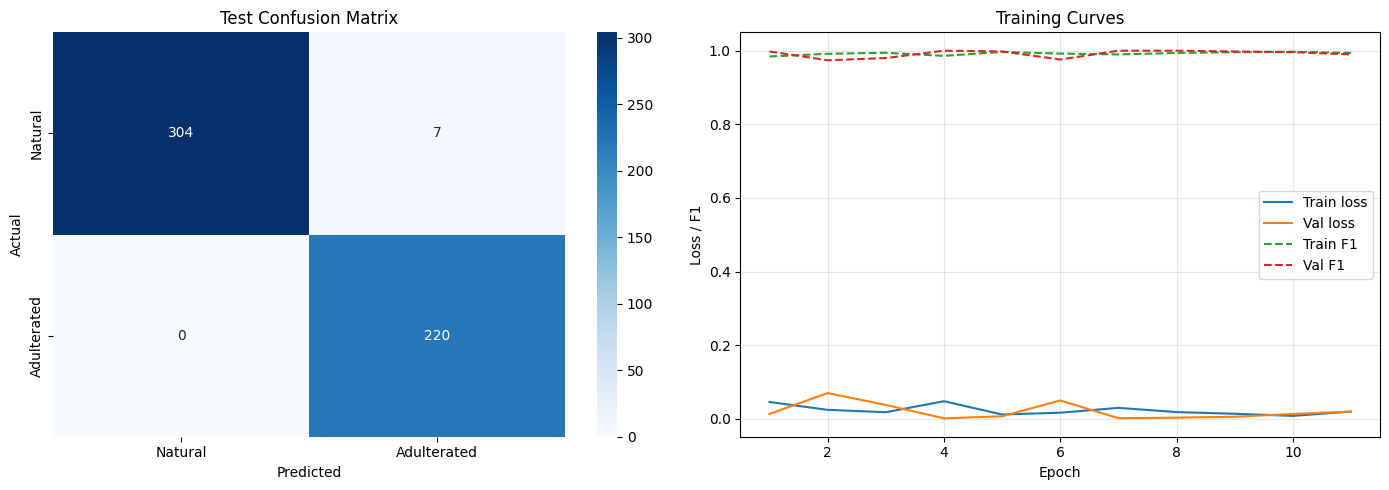


Saved:
  Checkpoint : /content/drive/MyDrive/best_banana_multimodal.pth
  Curves     : /content/drive/MyDrive/banana_test_results.png


In [ ]:
# ============================================================
# Load best and evaluate on test
# ============================================================
ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
print(f'Loaded best model from epoch {ckpt["epoch"]}')

test_metrics, test_preds, test_labels, test_probs = eval_epoch(dl_test)

print('\n' + '='*70)
print('TEST RESULTS')
print('='*70)
for k, v in test_metrics.items():
    print(f'{k}: {v:.4f}')

print('\nClassification Report:')
print(classification_report(test_labels, test_preds,
                            target_names=['Natural', 'Adulterated'],
                            digits=4))

cm = confusion_matrix(test_labels, test_preds)
print('\nConfusion Matrix:')
print(pd.DataFrame(cm,
                    index=['Actual Natural', 'Actual Adulterated'],
                    columns=['Pred Natural', 'Pred Adulterated']))

# Plot
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Natural', 'Adulterated'],
            yticklabels=['Natural', 'Adulterated'])
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')
ax[0].set_title('Test Confusion Matrix')

# Training curves
hist = pd.DataFrame(history)
ax[1].plot(hist['epoch'], hist['tr_loss'], label='Train loss')
ax[1].plot(hist['epoch'], hist['va_loss'], label='Val loss')
ax[1].plot(hist['epoch'], hist['tr_f1'],   label='Train F1', linestyle='--')
ax[1].plot(hist['epoch'], hist['va_f1'],   label='Val F1',   linestyle='--')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss / F1')
ax[1].set_title('Training Curves')
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/banana_test_results.png', dpi=150)
plt.show()

print('\nSaved:')
print(f'  Checkpoint : {CHECKPOINT_PATH}')
print(f'  Curves     : /content/drive/MyDrive/banana_test_results.png')